# 3. The model

The goal is a model whose decisions can be **explained** to applicants rather
than the most accurate one.
Counterfactual explanations ("the application would be accepted had the number
of credit checks been at most 2") are only useful when they refer to features
that are easy to understand and can, in principle, change.

First, how well do common models do with all the features?

In [1]:
import warnings
warnings.filterwarnings('ignore')
from fico_xml import data, evaluation, model, preprocessing

raw = data.load_raw()
clean = preprocessing.clean(raw)
complete = clean.data.dropna()
X_all = complete.drop(columns=['MaxDelqEver', 'MaxDelq2PublicRecLast12M'])
y_all = clean.target[complete.index]
X_all.shape

(2131, 50)

In [2]:
all_features = evaluation.compare(evaluation.classifiers(), X_all, y_all)
all_features[['train accuracy', 'test accuracy', 'test F1 (Good)']].round(3)

,train accuracy,test accuracy,test F1 (Good)
logistic regression,0.711,0.694,0.541
random forest (min_samples_split=175),0.715,0.687,0.518
random forest (max_depth=4),0.724,0.686,0.503
Gaussian naive Bayes,0.681,0.675,0.562
decision tree,0.736,0.660,0.499
Bernoulli naive Bayes,0.665,0.658,0.520
SVM (C=0.5),0.648,0.646,0.245
k-NN (k=30),0.663,0.638,0.359
SVM (C=0.1),0.614,0.614,0.000
perceptron,0.561,0.563,0.374


The best models reach a test accuracy of about 0.69, which is no better than
the threshold on the external risk estimate alone (about 0.71, first notebook):
the data hold limited signal and more complex models do not help.

## Ten count features

The original model uses ten **counts** from the credit record -- numbers of
accounts, overdue accounts and credit checks.
They are easy to understand and their counterfactuals are whole numbers
("at most 2 credit checks").
Applicants with a missing value of any of them (no usable value in the record)
are not used:

In [3]:
X, y = model.model_data(clean)
model.MODEL_FEATURES, X.shape

(['NumTotalTrades',
  'NumSatisfactoryTrades',
  'NumTrades60Ever2DerogPubRec',
  'NumTrades90Ever2DerogPubRec',
  'NumTradesOpeninLast12M',
  'NumRevolvingTradesWBalance',
  'NumInstallTradesWBalance',
  'NumBank2NatlTradesWHighUtilization',
  'NumInqLast6Mexcl7days',
  'NumInqLast7DCalc'],
 (7084, 10))

In [4]:
count_features = evaluation.compare(evaluation.classifiers(), X, y)
count_features[['train accuracy', 'test accuracy', 'test F1 (Good)']].round(3)

,train accuracy,test accuracy,test F1 (Good)
logistic regression,0.688,0.687,0.698
SVM (C=0.5),0.679,0.676,0.693
random forest (min_samples_split=175),0.699,0.675,0.664
decision tree,0.712,0.662,0.656
random forest (max_depth=4),0.669,0.660,0.647
k-NN (k=30),0.685,0.659,0.679
SVM (C=0.1),0.657,0.656,0.668
Bernoulli naive Bayes,0.640,0.639,0.632
perceptron,0.602,0.603,0.582
Gaussian naive Bayes,0.595,0.595,0.675


The ten counts lose only a little accuracy compared with all the features.

## The decision tree

A decision tree of depth 7 whose leaves hold at least 100 applicants keeps the
explanations short and the model readable.

In [5]:
tree = model.train(clean)
model.fingerprint(tree.classifier) == model.ORIGINAL_FINGERPRINT

True

It is exactly the original tree (the fingerprint confirms its structure).
Its cross-validated accuracy:

In [6]:
from sklearn.tree import DecisionTreeClassifier

folds = evaluation.cross_validate(
    DecisionTreeClassifier(random_state=0, **model.ORIGINAL_PARAMETERS),
    X,
    y)
folds.mean().round(3)

train accuracy     0.682
train F1 (Good)    0.673
test accuracy      0.659
test F1 (Good)     0.647
dtype: float64

The tree has 42 leaves;
its first levels:

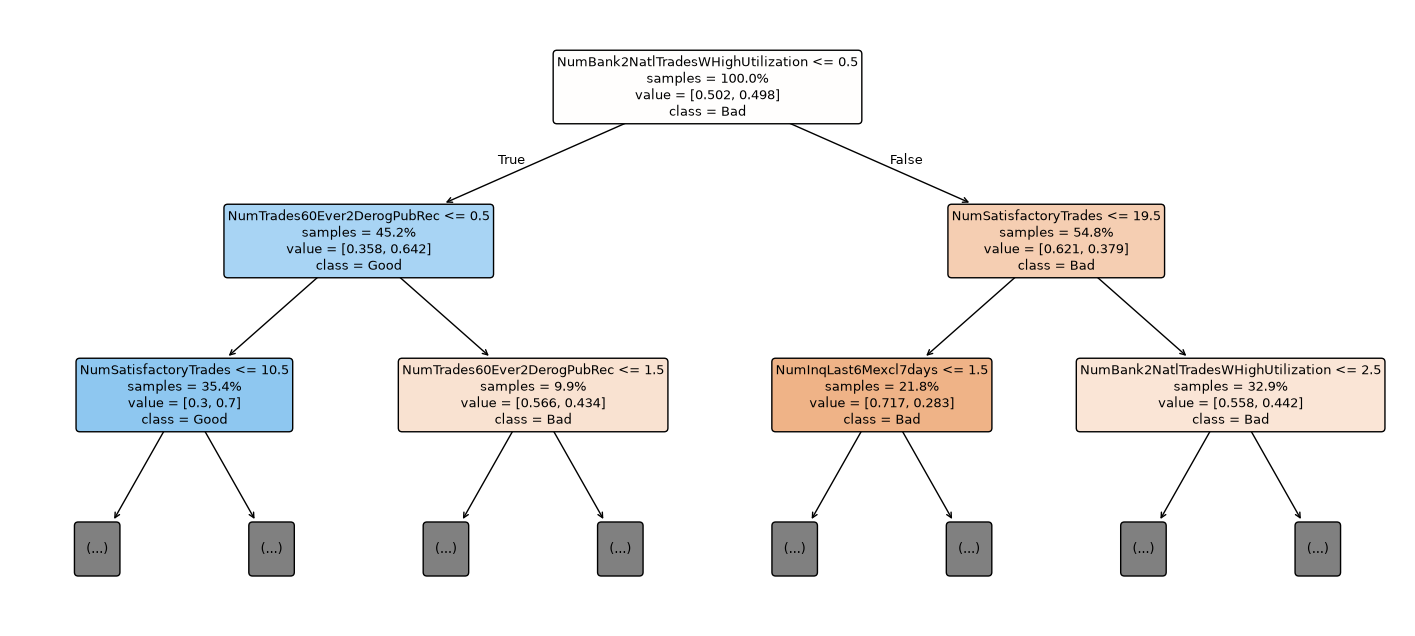

In [7]:
import matplotlib.pyplot as plt
from fico_xml.explain import plot_tree

fig, ax = plt.subplots(figsize=(18, 8))
_ = plot_tree(tree, ax=ax, max_depth=2, fontsize=9)

The features the tree relies on most:

In [8]:
tree.feature_importance().round(3)

NumBank2NatlTradesWHighUtilization    0.477
NumTrades60Ever2DerogPubRec           0.189
NumSatisfactoryTrades                 0.181
NumTradesOpeninLast12M                0.044
NumInqLast6Mexcl7days                 0.044
NumRevolvingTradesWBalance            0.029
NumTotalTrades                        0.024
NumInstallTradesWBalance              0.011
NumTrades90Ever2DerogPubRec           0.000
NumInqLast7DCalc                      0.000
Name: importance, dtype: float64